In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()


Saving alay_English_Sentiment_Preprocessed.csv to alay_English_Sentiment_Preprocessed.csv


In [3]:
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nSentiment distribution:")
print(df["Sentiment (All)"].value_counts())

df.head()


Dataset shape: (599, 4)

Column names:
['Tweets', 'Sentiment (All)', 'Cleaned_Tweets', 'Tokens']

Sentiment distribution:
Sentiment (All)
NEUTRAL     479
POSITIVE    104
NEGATIVE     16
Name: count, dtype: int64


,Tweets,Sentiment (All),Cleaned_Tweets,Tokens
0,and allah never fails his promise quran mydin ...,POSITIVE,and allah never fails his promise quran mydin ...,"['and', 'allah', 'never', 'fails', 'his', 'pro..."
1,threats kenapa usia muda kena medikal kad ekan...,NEUTRAL,threats kenapa usia muda kena medikal kad ekan...,"['threats', 'kenapa', 'usia', 'muda', 'kena', ..."
2,ton long march b rocket,NEUTRAL,ton long march b rocket,"['ton', 'long', 'march', 'b', 'rocket']"
3,our recommended item michizakura aiyama,NEUTRAL,our recommended item michizakura aiyama,"['our', 'recommended', 'item', 'michizakura', ..."
4,nak order vcs ws,NEUTRAL,nak order vcs ws,"['nak', 'order', 'vcs', 'ws']"


In [4]:
data = df[["Cleaned_Tweets", "Sentiment (All)"]].dropna().copy()

data = data[data["Cleaned_Tweets"].str.strip() != ""]
data = data.drop_duplicates(subset=["Cleaned_Tweets"])

X = data["Cleaned_Tweets"]
y = data["Sentiment (All)"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total usable records:", len(data))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Total usable records: 599
Training samples: 479
Testing samples: 120

Training sentiment distribution:
Sentiment (All)
NEUTRAL     383
POSITIVE     83
NEGATIVE     13
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment (All)
NEUTRAL     96
POSITIVE    21
NEGATIVE     3
Name: count, dtype: int64


In [5]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed successfully!")

print("\nTraining feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

print("\nTotal features:", len(tfidf.get_feature_names_out()))

print("\nSample features:")
print(tfidf.get_feature_names_out()[:20])


TF-IDF transformation completed successfully!

Training feature shape: (479, 4075)
Testing feature shape: (120, 4075)

Total features: 4075

Sample features:
['aaaaaaaaaa' 'aagya' 'aagya swaad' 'aamiin' 'aamiin biar' 'aap'
 'aap mein' 'aap sab' 'aaron' 'aaron chiasoh' 'abg' 'abg azira' 'abg jom'
 'abg jomla' 'abg knpe' 'accepted' 'accepted klia' 'accepted pbb'
 'achanta' 'achanta sharath']


In [6]:
nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Model Trained Successfully!")

print("\nNaive Bayes Accuracy:")
print(f"{nb_accuracy * 100:.2f}%")

print("\nNaive Bayes Classification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    zero_division=0
))


Naive Bayes Model Trained Successfully!

Naive Bayes Accuracy:
84.17%

Naive Bayes Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.00      0.00      0.00         3
     NEUTRAL       0.83      1.00      0.91        96
    POSITIVE       1.00      0.24      0.38        21

    accuracy                           0.84       120
   macro avg       0.61      0.41      0.43       120
weighted avg       0.84      0.84      0.80       120



In [7]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced",
    C=1.0
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Model Trained Successfully!")

print("\nLogistic Regression Accuracy:")
print(f"{lr_accuracy * 100:.2f}%")

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))


Logistic Regression Model Trained Successfully!

Logistic Regression Accuracy:
86.67%

Logistic Regression Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.67      0.67      0.67         3
     NEUTRAL       0.86      0.99      0.92        96
    POSITIVE       1.00      0.33      0.50        21

    accuracy                           0.87       120
   macro avg       0.84      0.66      0.70       120
weighted avg       0.88      0.87      0.84       120



In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy
    ],
    "Precision": [
        precision_score(y_test, nb_predictions,
                        average="macro", zero_division=0),
        precision_score(y_test, lr_predictions,
                        average="macro", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, nb_predictions,
                     average="macro", zero_division=0),
        recall_score(y_test, lr_predictions,
                     average="macro", zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, nb_predictions,
                 average="macro", zero_division=0),
        f1_score(y_test, lr_predictions,
                 average="macro", zero_division=0)
    ]
})

print("Model Performance Comparison")
display(results.round(4))


Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.8417,0.6116,0.4127,0.4315
1,Logistic Regression,0.8667,0.8434,0.6632,0.6963


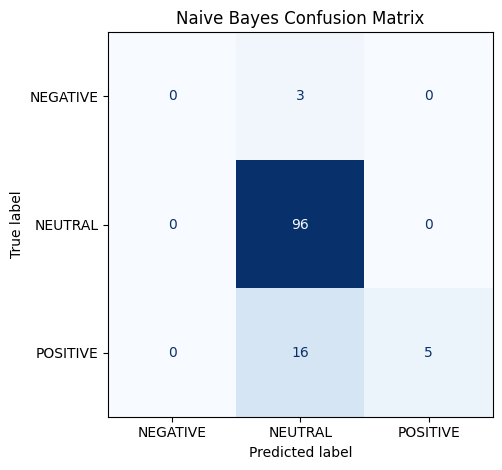

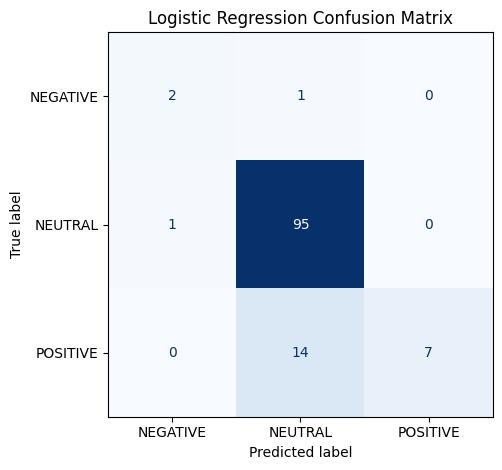

In [9]:
labels = ["NEGATIVE", "NEUTRAL", "POSITIVE"]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    labels=labels,
    cmap="Blues",
    colorbar=False
)

plt.title("Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    labels=labels,
    cmap="Blues",
    colorbar=False
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


In [10]:
sample_texts = [
    "saya sangat happy hari ini",
    "service sangat teruk disappointing",
    "saya pergi ke kedai hari ini",
    "makanan ni very delicious",
    "i hate this bad service",
    "meeting bermula pukul 10 pagi"
]

sample_features = tfidf.transform(sample_texts)

sample_predictions = lr_model.predict(sample_features)

sample_results = pd.DataFrame({
    "Input Text": sample_texts,
    "Predicted Sentiment": sample_predictions
})

display(sample_results)


,Input Text,Predicted Sentiment
0,saya sangat happy hari ini,NEUTRAL
1,service sangat teruk disappointing,NEUTRAL
2,saya pergi ke kedai hari ini,NEUTRAL
3,makanan ni very delicious,NEUTRAL
4,i hate this bad service,NEUTRAL
5,meeting bermula pukul 10 pagi,NEUTRAL


In [11]:
print("Malay-English Sentiment Analysis System")
print("---------------------------------------")

user_text = input("Enter a Malay-English sentence: ")

if user_text.strip():

    text_features = tfidf.transform([user_text])

    prediction = lr_model.predict(text_features)[0]

    probabilities = lr_model.predict_proba(text_features)[0]

    confidence = max(probabilities) * 100

    print("\nInput Text:", user_text)
    print("Predicted Sentiment:", prediction)
    print(f"Model Confidence: {confidence:.2f}%")

else:
    print("Please enter a valid sentence.")


Malay-English Sentiment Analysis System
---------------------------------------
Enter a Malay-English sentence: Saya sangat happy dengan service ini

Input Text: Saya sangat happy dengan service ini
Predicted Sentiment: NEUTRAL
Model Confidence: 50.79%


In [13]:
import sys
import sklearn
import matplotlib

print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)
print("Matplotlib Version:", matplotlib.__version__)


Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas Version: 2.2.3
NumPy Version: 2.4.6
Scikit-learn Version: 1.6.1
Matplotlib Version: 3.10.0
